# When does AGG actually rebalance?

AGG (iShares Core US Aggregate Bond ETF) holds a sample of bonds that tracks the Bloomberg US Aggregate index. This
notebook downloads AGG's holdings file for **every trading day** in a window and measures how much the portfolio
changes from one day to the next, to see whether it changes daily, monthly, quarterly...

What to expect:
- **Every day:** a handful of CUSIPs added/dropped and a few hundred positions resized (new issues bought early,
  sampling trades, creations/redemptions). Small turnover.
- **Last trading day of the month:** the index rebalance. 60-100 bonds dropped (mostly bonds falling under the
  1-year maturity floor), large Treasury turnover.
- **Mid-month (~7th-14th):** TBA rolls (this month's TBA contract sold, next month's bought). Large turnover, but only
  in TBAs.

The data pipeline (`data_cleaning/holdings.py`) only uses the month-end file, as the start-of-month portfolio. The
last section checks how much that misses.

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "workbook" else Path.cwd()
sys.path.insert(0, str(ROOT))
from data_cleaning import config as C
from data_cleaning.holdings import read_holdings

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DAILY_DIR = C.RAW_DIR / "agg_holdings_daily"     # gitignored, like the rest of data/raw
START, END = "2023-12-29", "2024-06-30"           # change to look at another window (1 request per weekday)

## 1. Download one holdings file per trading day

Same BlackRock fund-document API as the pipeline (`config.AGG_HOLDINGS_API`). Files already in `DAILY_DIR` are
skipped; weekends/holidays return an empty body and are not saved. About 2 minutes per 6 months.

In [2]:
import requests
def _get(session, url, attempts=4):
    """GET with retries: the API occasionally stalls for a minute or returns a 5xx."""
    for i in range(attempts):
        try:
            r = session.get(url, timeout=60)
            r.raise_for_status()
            return r
        except (requests.Timeout, requests.ConnectionError, requests.HTTPError):
            if i == attempts - 1:
                raise
            time.sleep(10 * (i + 1))

DAILY_DIR.mkdir(parents=True, exist_ok=True)
session = requests.Session()
new = 0
for d in pd.bdate_range(START, END):
    path = DAILY_DIR / f"AGG_{d:%Y%m%d}.csv"
    if path.exists() or d > pd.Timestamp.today():
        continue
    r = _get(session, C.AGG_HOLDINGS_API.format(date=d))
    if b"Holdings as of" in r.content[:300]:
        path.write_bytes(r.content)
        new += 1
    time.sleep(0.5)
files = sorted(p for p in DAILY_DIR.glob("AGG_*.csv") if START.replace("-", "") <= p.stem[4:] <= END.replace("-", ""))
print(f"{new} new files, {len(files)} trading days in the window")

0 new files, 125 trading days in the window


## 2. Load every day into one long table

One row per (date, cusip): all fixed-income rows of the file (not just the sectors the model uses), grouped into
`treasury` / `corporate` / `mbs` (pass-through pools) / `tba` / `other` (CMBS, ABS, agencies, sovereigns...).
Duplicate CUSIP rows are summed.

In [3]:
def group(df):
    g = df["agg_sector"].map(lambda s: C.ASSET_TYPE.get(C.SECTOR_MAP.get(s, ""), "other"))
    return g.where(~df["name"].str.contains("TBA", case=False, na=False), "tba")

frames = []
for p in files:
    df, asof = read_holdings(p)
    b = df[df["cusip"].str.fullmatch(r"[A-Z0-9]{9}", na=False) & (df["asset_class"] == "Fixed Income")].copy()
    b["grp"] = group(b)
    b = b.groupby("cusip").agg(name=("name", "first"), grp=("grp", "first"), sector=("agg_sector", "first"),
                               maturity=("agg_maturity_date", "first"), coupon=("agg_coupon_pct", "first"),
                               par=("agg_par_value", "sum"), mv=("agg_market_value", "sum")).reset_index()
    frames.append(b.assign(date=asof))
daily = pd.concat(frames, ignore_index=True)
daily["par_w"] = daily["par"] / daily.groupby("date")["par"].transform("sum")   # weight by face: ignores price moves
daily["mv_w"] = daily["mv"] / daily.groupby("date")["mv"].transform("sum")
dates = pd.DatetimeIndex(sorted(daily["date"].unique()))
print(f"{len(daily):,} rows, {len(dates)} days, {daily['cusip'].nunique():,} distinct CUSIPs")
daily.head()

1,448,259 rows, 125 days, 12,513 distinct CUSIPs


,cusip,name,grp,sector,maturity,coupon,par,mv,date,par_w,mv_w
0,00037BAC6,ABB FINANCE USA INC,corporate,Industrial,2042-05-08,4.38,280000.0,260140.19,2023-12-29,0.000003,0.000003
1,00037BAF9,ABB FINANCE USA INC,corporate,Industrial,2028-04-03,3.80,800000.0,794167.14,2023-12-29,0.000007,0.000008
2,001055AQ5,AFLAC INCORPORATED,corporate,Financial Institutions,2026-10-15,2.88,1937000.0,1853647.49,2023-12-29,0.000018,0.000018
3,001055AR3,AFLAC INCORPORATED,corporate,Financial Institutions,2046-10-15,4.00,1381000.0,1142548.82,2023-12-29,0.000013,0.000011
4,001055AY8,AFLAC INCORPORATED,corporate,Financial Institutions,2049-01-15,4.75,3008000.0,2899582.77,2023-12-29,0.000028,0.000029


## 3. Day-over-day changes

For each pair of consecutive trading days:
- `added` / `dropped`: CUSIPs that appear / disappear
- `resized_gt1pct`: positions held both days whose par changed by more than 1%
- `turnover_pct`: one-way turnover in **par** weights, 0.5 x sum |w_t - w_t-1|, so price moves don't count.
  Split by asset group in the `to_*` columns.

In [4]:
par = daily.pivot_table(index="cusip", columns="date", values="par", aggfunc="sum")
par_w = daily.pivot_table(index="cusip", columns="date", values="par_w", aggfunc="sum").fillna(0)
grp = daily.drop_duplicates("cusip", keep="last").set_index("cusip")["grp"]

rows = []
for a, b in zip(dates[:-1], dates[1:]):
    pa, pb = par[a], par[b]
    both = pa.notna() & pb.notna()
    dw = (par_w[b] - par_w[a]).abs()
    r = {"date": b, "positions": int(pb.notna().sum()),
         "added": int((pb.notna() & pa.isna()).sum()), "dropped": int((pa.notna() & pb.isna()).sum()),
         "resized_gt1pct": int(((pb[both] / pa[both] - 1).abs() > 0.01).sum()),
         "turnover_pct": 50 * dw.sum()}
    r.update({f"to_{g}": 50 * v for g, v in dw.groupby(grp).sum().items()})
    rows.append(r)
chg = pd.DataFrame(rows).set_index("date")

# label each day: last trading day of its month, first trading day, or other
period = chg.index.to_period("M")
all_days = pd.Series(dates.to_period("M"), index=dates)
chg["day_type"] = np.select([chg.index.isin(all_days.groupby(all_days).tail(1).index),
                             chg.index.isin(all_days.groupby(all_days).head(1).index)],
                            ["month_end", "month_start"], "other")
chg.round(3)

,positions,added,dropped,resized_gt1pct,turnover_pct,to_corporate,to_mbs,to_other,to_tba,to_treasury,day_type
date,,,,,,,,,,,
2024-01-02,11312,25,0,561,0.233,0.078,0.029,0.011,0.004,0.112,month_start
2024-01-03,11322,10,0,220,0.053,0.026,0.002,0.004,0.000,0.020,other
2024-01-04,11331,9,0,303,0.337,0.023,0.145,0.002,0.140,0.027,other
2024-01-05,11336,5,0,993,0.274,0.030,0.118,0.004,0.068,0.055,other
2024-01-08,11355,19,0,177,0.313,0.029,0.041,0.011,0.199,0.033,other
...,...,...,...,...,...,...,...,...,...,...,...
2024-06-24,11722,9,35,3,0.151,0.060,0.037,0.007,0.028,0.018,other
2024-06-25,11705,7,24,177,0.124,0.049,0.009,0.003,0.034,0.030,other
2024-06-26,11694,6,17,140,0.065,0.040,0.001,0.012,0.000,0.012,other


In [5]:
to_cols = [c for c in chg if c.startswith("to_")]
print("Average per day, by day type:")
chg.groupby("day_type")[["added", "dropped", "resized_gt1pct", "turnover_pct"] + to_cols].mean().round(3)

Average per day, by day type:


,added,dropped,resized_gt1pct,turnover_pct,to_corporate,to_mbs,to_other,to_tba,to_treasury
day_type,,,,,,,,,
month_end,4.500,41.833,371.333,0.831,0.136,0.039,0.029,0.042,0.584
month_start,10.833,1.500,446.333,0.213,0.058,0.029,0.009,0.030,0.087
other,10.214,5.054,326.232,0.286,0.037,0.028,0.008,0.165,0.048


In [6]:
print("Biggest drop days and biggest Treasury-turnover days:")
display(chg.nlargest(8, "dropped")[["day_type", "dropped", "added", "to_treasury", "turnover_pct"]].round(3))
display(chg.nlargest(8, "to_treasury")[["day_type", "dropped", "added", "to_treasury", "turnover_pct"]].round(3))

Biggest drop days and biggest Treasury-turnover days:


,day_type,dropped,added,to_treasury,turnover_pct
date,,,,,
2024-03-27,other,97,9,0.091,0.433
2024-05-31,month_end,90,4,0.738,1.061
2024-02-29,month_end,82,3,0.770,1.185
2024-01-31,month_end,63,5,0.410,0.680
2024-06-24,other,35,9,0.018,0.151
2024-04-15,other,34,6,0.067,0.208
2024-04-12,other,32,12,0.066,1.117
2024-06-25,other,24,7,0.030,0.124


,day_type,dropped,added,to_treasury,turnover_pct
date,,,,,
2024-02-29,month_end,82,3,0.770,1.185
2024-05-31,month_end,90,4,0.738,1.061
2024-03-28,month_end,3,0,0.629,0.722
2024-06-28,month_end,6,8,0.538,0.791
2024-04-30,month_end,7,7,0.418,0.544
2024-01-31,month_end,63,5,0.410,0.680
2024-02-13,other,11,24,0.203,1.221
2024-03-25,other,0,11,0.183,0.495


## 4. Plots

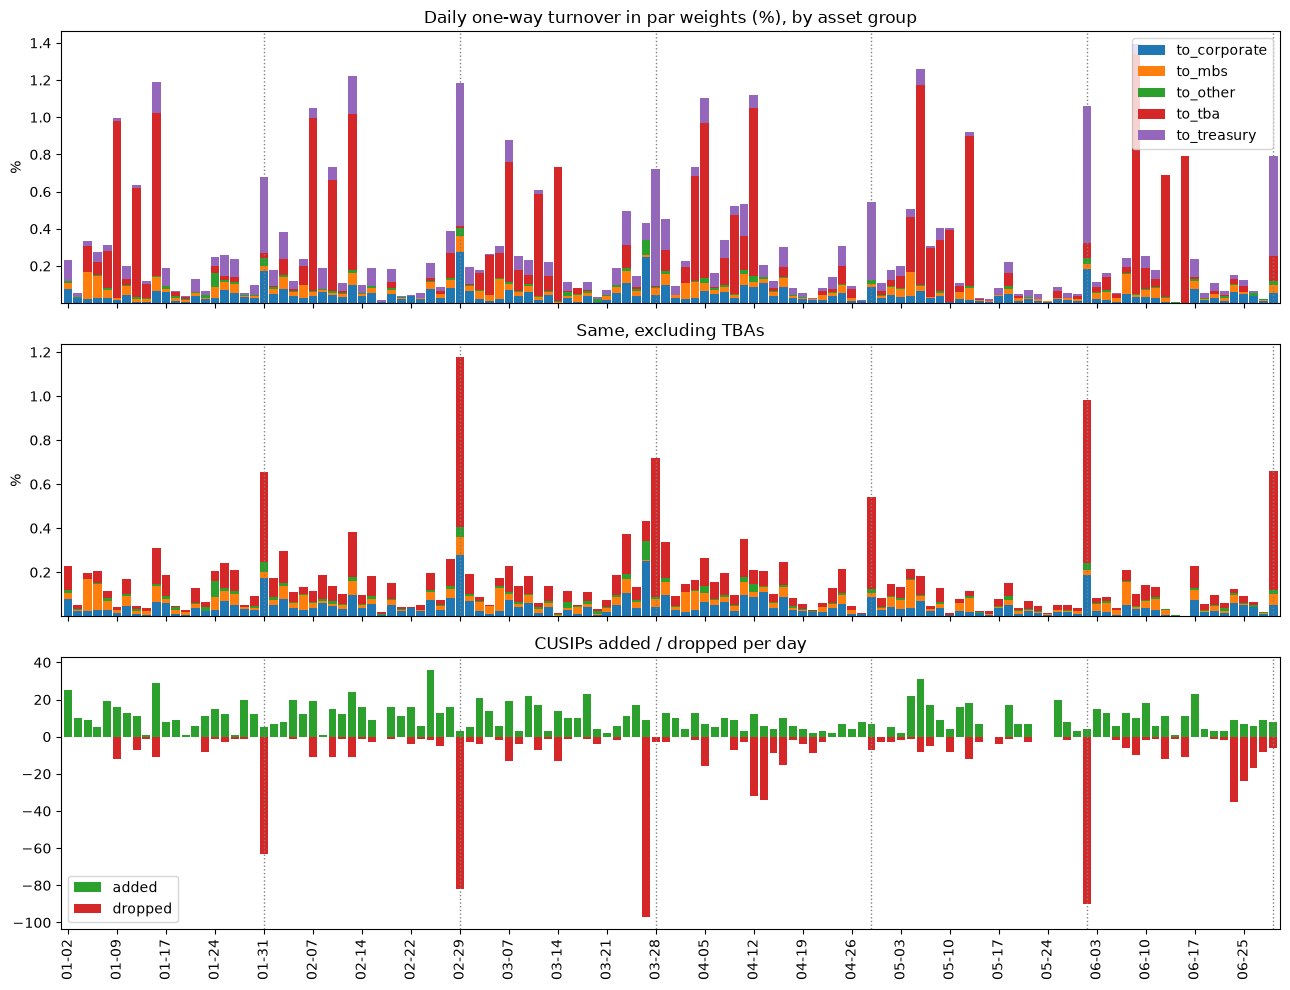

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
month_ends = chg.index[chg["day_type"] == "month_end"]

chg[to_cols].plot.bar(stacked=True, ax=axes[0], width=0.9)
axes[0].set_title("Daily one-way turnover in par weights (%), by asset group")
axes[0].set_ylabel("%")

chg[[c for c in to_cols if c != "to_tba"]].plot.bar(stacked=True, ax=axes[1], width=0.9, legend=False)
axes[1].set_title("Same, excluding TBAs")
axes[1].set_ylabel("%")

axes[2].bar(range(len(chg)), chg["added"], label="added", color="tab:green")
axes[2].bar(range(len(chg)), -chg["dropped"], label="dropped", color="tab:red")
axes[2].set_title("CUSIPs added / dropped per day")
axes[2].legend()

for ax in axes:
    for d in month_ends:
        ax.axvline(chg.index.get_loc(d), color="grey", ls=":", lw=1)
ticks = range(0, len(chg), 5)
axes[2].set_xticks(list(ticks))
axes[2].set_xticklabels([chg.index[i].strftime("%m-%d") for i in ticks], rotation=90)
plt.tight_layout()

Dotted lines are the last trading day of each month. The top panel is dominated by mid-month TBA rolls; once TBAs are
removed (middle) the month-end spikes stand out, and the drops (bottom) cluster there.

## 5. What gets dropped at month-end?

The index drops bonds once they have less than 1 year to maturity. Compare the remaining life of bonds dropped on
month-end days with those dropped on other days.

In [8]:
prev = {b: a for a, b in zip(dates[:-1], dates[1:])}
last_seen = daily.set_index(["date", "cusip"])
drops = []
for d in chg.index:
    a = prev[d]
    gone = par.index[par[a].notna() & par[d].isna()]
    x = last_seen.loc[a].loc[gone, ["name", "grp", "sector", "maturity", "coupon", "par_w"]].copy()
    drops.append(x.assign(drop_date=d, day_type=chg.loc[d, "day_type"]).reset_index())
drops = pd.concat(drops, ignore_index=True)
drops["years_left"] = (drops["maturity"] - drops["drop_date"]).dt.days / 365.25
drops["under_1y"] = drops["years_left"] < 1

print("Dropped CUSIPs by day type and asset group:")
display(pd.crosstab(drops["grp"], drops["day_type"], margins=True))
print("Share with < 1 year to maturity:")
display(drops.groupby("day_type")["under_1y"].mean().round(3))
drops[drops["day_type"] == "month_end"].sort_values("par_w", ascending=False).head(15)

Dropped CUSIPs by day type and asset group:


day_type,month_end,month_start,other,All
grp,,,,
corporate,190,7,312,509
mbs,1,0,12,13
other,34,2,62,98
tba,0,0,180,180
treasury,26,0,0,26
All,251,9,566,826


Share with < 1 year to maturity:


day_type
month_end      0.869
month_start    0.111
other          0.703
Name: under_1y, dtype: float64

,cusip,name,grp,sector,maturity,coupon,par_w,drop_date,day_type,years_left,under_1y
102,912828YV6,TREASURY NOTE,treasury,Treasury,2024-11-30,1.50,0.001801,2024-01-31,month_end,0.832307,True
823,912828XB1,TREASURY NOTE,treasury,Treasury,2025-05-15,2.13,0.001724,2024-06-28,month_end,0.878850,True
394,912828J27,TREASURY NOTE,treasury,Treasury,2025-02-15,2.00,0.001584,2024-03-28,month_end,0.887064,True
233,91282CGD7,TREASURY NOTE,treasury,Treasury,2024-12-31,4.25,0.001545,2024-02-29,month_end,0.837782,True
395,91282CDS7,TREASURY NOTE,treasury,Treasury,2025-01-15,1.13,0.001385,2024-03-28,month_end,0.802190,True
232,91282CDN8,TREASURY NOTE,treasury,Treasury,2024-12-15,1.00,0.001347,2024-02-29,month_end,0.793977,True
825,91282CEQ0,TREASURY NOTE,treasury,Treasury,2025-05-15,2.75,0.001324,2024-06-28,month_end,0.878850,True
542,91282CDZ1,TREASURY NOTE,treasury,Treasury,2025-02-15,1.50,0.001303,2024-04-30,month_end,0.796715,True
231,912828YY0,TREASURY NOTE,treasury,Treasury,2024-12-31,1.75,0.001250,2024-02-29,month_end,0.837782,True
680,91282CGN5,TREASURY NOTE,treasury,Treasury,2025-02-28,4.63,0.001066,2024-05-31,month_end,0.747433,True


## 6. Explore a single bond

Pick any CUSIP (e.g. one from the drops table above, or a TBA) and see its par and weight through time.

{'name': 'TREASURY NOTE', 'grp': 'treasury', 'maturity': Timestamp('2024-11-30 00:00:00')}


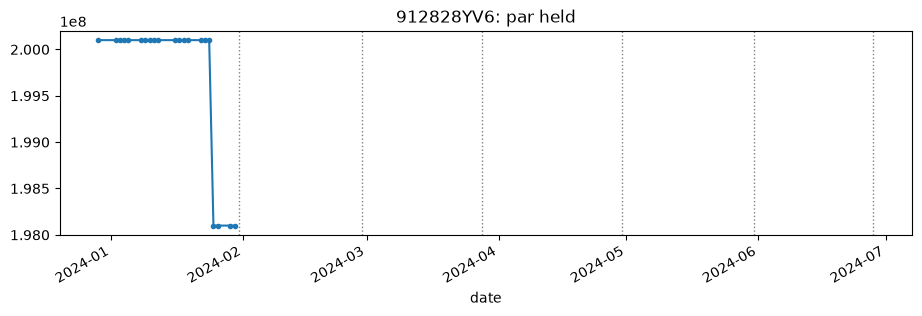

In [9]:
example = drops.loc[drops["day_type"] == "month_end"].sort_values("par_w").iloc[-1]["cusip"]   # change me
h = daily[daily["cusip"] == example].set_index("date")
print(h[["name", "grp", "maturity"]].iloc[0].to_dict())
ax = h["par"].plot(figsize=(11, 3), marker=".", title=f"{example}: par held")
for d in month_ends:
    ax.axvline(d, color="grey", ls=":", lw=1)

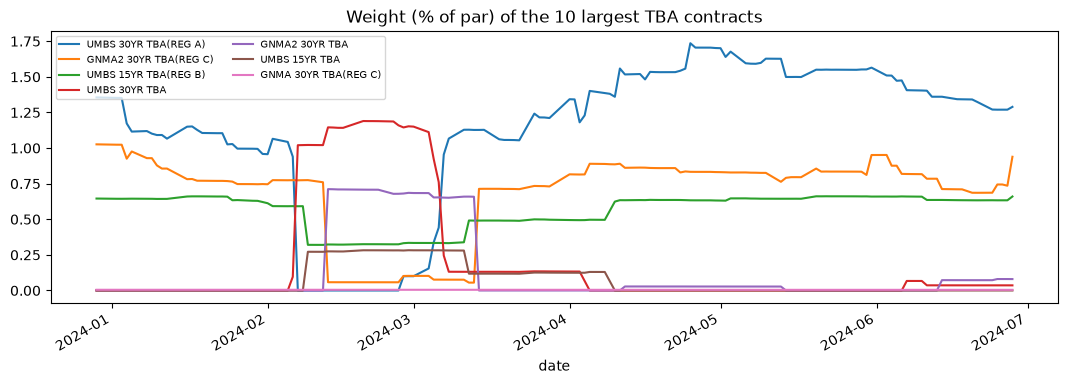

In [10]:
# TBA rolls: total par in TBAs by contract, per day. Each contract is replaced by the next month's around mid-month.
tba = daily[daily["grp"] == "tba"].pivot_table(index="date", columns="name", values="par_w", aggfunc="sum").fillna(0)
top = tba.sum().nlargest(10).index
ax = (100 * tba[top]).plot(figsize=(13, 4), title="Weight (% of par) of the 10 largest TBA contracts")
ax.legend(fontsize=7, ncol=2)

## 7. How much does the monthly snapshot miss?

The pipeline uses the file from the last trading day of month m-1 for the whole of month m. For each day, how much
of that day's (non-TBA) weight is in bonds that were in the start-of-month file, and how far are the weights from the
start-of-month weights?

,weight_in_start_portfolio,drift_vs_start_pct
count,124.0000,124.0000
mean,0.9960,1.2466
std,0.0029,0.6440
min,0.9857,0.0786
25%,0.9948,0.8090
50%,0.9964,1.2303
75%,0.9980,1.6329
max,1.0000,3.0511


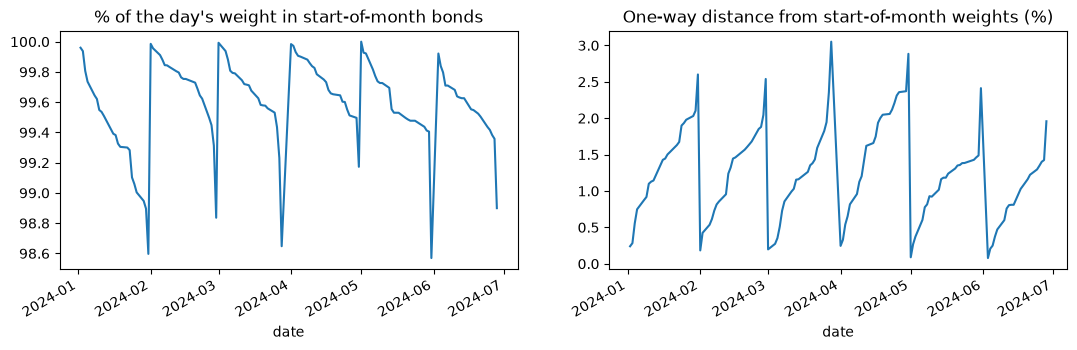

In [11]:
nt = daily[daily["grp"] != "tba"].copy()
nt["w"] = nt["par"] / nt.groupby("date")["par"].transform("sum")
w = nt.pivot_table(index="cusip", columns="date", values="w").fillna(0)
start_file = {m: d for m, d in pd.Series(dates, index=dates.to_period("M")).groupby(level=0).max().items()}

rows = []
for d in dates:
    ref = start_file.get(d.to_period("M") - 1)
    if ref is None:
        continue
    held = w[ref] > 0
    rows.append({"date": d, "weight_in_start_portfolio": w.loc[held, d].sum(),
                 "drift_vs_start_pct": 50 * (w[d] - w[ref]).abs().sum()})
miss = pd.DataFrame(rows).set_index("date")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
(100 * miss["weight_in_start_portfolio"]).plot(ax=ax[0], title="% of the day's weight in start-of-month bonds")
miss["drift_vs_start_pct"].plot(ax=ax[1], title="One-way distance from start-of-month weights (%)")
miss.describe().round(4)

Within a month, almost all of the day's weight sits in bonds that were already in the start-of-month file, and the
weights drift by only a little before resetting at the next month-end. That is why the pipeline treats holdings as
fixed within the month.